# CIFAR-10 Assignment 2
This notebook is designed to run top-to-bottom. It creates a balanced 500-image training subset (400 train / 100 validation), trains a compact Inception-style CNN, runs augmentation experiments, evaluates clean and shifted test data, and performs error analysis/TTA.


## 1. Imports and configuration

In [1]:
import os, copy, random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import datasets, transforms
from torchvision.transforms import InterpolationMode
from sklearn.metrics import classification_report, confusion_matrix

SEED = 42
DATA_DIR = "./data"
OUT = Path("./outputs")
CKPT = OUT / "checkpoints"
OUT.mkdir(exist_ok=True)
CKPT.mkdir(exist_ok=True)
BATCH_SIZE = 64
EPOCHS = 10
PATIENCE = 4
NUM_WORKERS = 0
RUN_FULL_ABLATION = True  # Set False for one seed/config smoke test
SEEDS = [17, 42, 123]
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CLASS_NAMES = ["airplane","automobile","bird","cat","deer","dog","frog","horse","ship","truck"]

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)
print("Device:", DEVICE)

Device: cpu


## 2. Download CIFAR-10 and make fixed, balanced 400/100 split

In [2]:
train_raw = datasets.CIFAR10(DATA_DIR, train=True, download=True, transform=None)
test_raw = datasets.CIFAR10(DATA_DIR, train=False, download=True, transform=None)
targets = np.asarray(train_raw.targets)
rng = np.random.default_rng(SEED)

selected = []
for c in range(10):
    selected.extend(rng.choice(np.where(targets == c)[0], 50, replace=False).tolist())
selected = np.asarray(selected, dtype=np.int64)
rng.shuffle(selected)

train_indices, val_indices = [], []
for c in range(10):
    ci = selected[targets[selected] == c].copy()
    rng.shuffle(ci)
    train_indices.extend(ci[:40].tolist())
    val_indices.extend(ci[40:].tolist())
train_indices = np.asarray(train_indices, dtype=np.int64)
val_indices = np.asarray(val_indices, dtype=np.int64)
np.savez(OUT / "data_split_indices.npz", selected=selected,
         train_indices=train_indices, val_indices=val_indices)

print("Subset:", len(selected), "| train:", len(train_indices), "| validation:", len(val_indices))
print("Train counts:", np.bincount(targets[train_indices], minlength=10))
print("Validation counts:", np.bincount(targets[val_indices], minlength=10))

Subset: 500 | train: 400 | validation: 100
Train counts: [40 40 40 40 40 40 40 40 40 40]
Validation counts: [10 10 10 10 10 10 10 10 10 10]


## 3. Compact Inception-style CNN

In [3]:
class ConvBNReLU(nn.Module):
    def __init__(self, cin, cout, k, padding=0):
        super().__init__()
        self.net = nn.Sequential(nn.Conv2d(cin, cout, k, padding=padding, bias=False),
                                 nn.BatchNorm2d(cout), nn.ReLU(inplace=True))
    def forward(self, x): return self.net(x)

class InceptionBlock(nn.Module):
    def __init__(self, cin, channels):
        super().__init__()
        b1, b3, b5, bp = channels
        self.b1 = ConvBNReLU(cin, b1, 1)
        self.b3 = nn.Sequential(ConvBNReLU(cin, b3, 1), ConvBNReLU(b3, b3, 3, 1))
        self.b5 = nn.Sequential(ConvBNReLU(cin, b5, 1), ConvBNReLU(b5, b5, 3, 1))
        self.bp = nn.Sequential(nn.AvgPool2d(3, stride=1, padding=1), ConvBNReLU(cin, bp, 1))
    def forward(self, x): return torch.cat([self.b1(x), self.b3(x), self.b5(x), self.bp(x)], dim=1)

class SmallCNN(nn.Module):
    def __init__(self, dropout=0.25):
        super().__init__()
        self.stem = nn.Sequential(ConvBNReLU(3, 32, 3, 1), nn.MaxPool2d(2))
        self.inc1 = InceptionBlock(32, (16,16,8,8))  # 48 channels
        self.reduce = nn.Sequential(ConvBNReLU(48,64,3,1), nn.MaxPool2d(2))
        self.inc2 = InceptionBlock(64, (24,24,12,12)) # 72 channels
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(),
                                  nn.Dropout(dropout), nn.Linear(72,10))
    def forward(self, x): return self.head(self.inc2(self.reduce(self.inc1(self.stem(x)))))

model_tmp = SmallCNN().to(DEVICE)
PARAMS = sum(p.numel() for p in model_tmp.parameters() if p.requires_grad)
print("Trainable parameters:", PARAMS)
assert PARAMS < 1_000_000

Trainable parameters: 45298


## 4. Augmentations, data loaders, training and evaluation helpers

In [4]:
class AddGaussianNoise:
    def __init__(self, std=0.02, p=0.3): self.std, self.p = std, p
    def __call__(self, x):
        if torch.rand(1).item() < self.p: x = x + torch.randn_like(x) * self.std
        return x.clamp(0, 1)

CONFIGS = ["none", "geometric", "photometric", "geometric_photometric", "random_erasing", "mixup"]

def train_transform(name):
    ops = []
    if name in ["geometric", "geometric_photometric", "random_erasing", "mixup"]:
        ops += [transforms.RandomCrop(32, padding=4), transforms.RandomHorizontalFlip()]
    if name in ["photometric", "geometric_photometric", "random_erasing", "mixup"]:
        ops += [transforms.ColorJitter(brightness=0.25, contrast=0.25, saturation=0.15)]
    ops += [transforms.ToTensor()]
    if name == "random_erasing":
        ops += [transforms.RandomErasing(p=0.5, scale=(0.05,0.20), ratio=(0.5,2.0), value=0)]
    if name == "mixup": ops += [AddGaussianNoise()]
    return transforms.Compose(ops)

def loaders(config, seed):
    set_seed(seed)
    tr = datasets.CIFAR10(DATA_DIR, train=True, download=False, transform=train_transform(config))
    va = datasets.CIFAR10(DATA_DIR, train=True, download=False, transform=transforms.ToTensor())
    return (DataLoader(Subset(tr, train_indices), batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS),
            DataLoader(Subset(va, val_indices), batch_size=128, shuffle=False, num_workers=NUM_WORKERS))

def evaluate(model, loader, predictions=False):
    model.eval(); loss_fn = nn.CrossEntropyLoss(reduction="sum")
    loss_sum, correct, total = 0.0, 0, 0
    ys, ps, probs_all = [], [], []
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            logits = model(x); loss_sum += loss_fn(logits, y).item()
            probs = torch.softmax(logits, 1); pred = logits.argmax(1)
            total += y.size(0); correct += (pred == y).sum().item()
            if predictions:
                ys.extend(y.cpu().numpy()); ps.extend(pred.cpu().numpy()); probs_all.extend(probs.cpu().numpy())
    result = {"loss": loss_sum/max(total,1), "accuracy": correct/max(total,1)}
    if predictions:
        result.update(labels=np.asarray(ys), predictions=np.asarray(ps), probabilities=np.asarray(probs_all))
    return result

def train_model(model, train_loader, val_loader, use_mixup=False):
    loss_fn = nn.CrossEntropyLoss()
    opt = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
    sched = optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", patience=2, factor=0.5)
    best_state, best_acc, wait = copy.deepcopy(model.state_dict()), -1.0, 0
    hist = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    for epoch in range(EPOCHS):
        model.train(); total_loss = 0.0; correct = 0; total = 0
        for x, y in train_loader:
            x, y = x.to(DEVICE), y.to(DEVICE); opt.zero_grad(set_to_none=True)
            if use_mixup:
                lam = float(np.random.beta(0.2, 0.2))
                perm = torch.randperm(x.size(0), device=DEVICE)
                logits = model(lam*x + (1-lam)*x[perm])
                loss = lam*loss_fn(logits,y) + (1-lam)*loss_fn(logits,y[perm])
            else:
                logits = model(x); loss = loss_fn(logits,y)
            loss.backward(); opt.step()
            total_loss += loss.item()*y.size(0); correct += (logits.argmax(1)==y).sum().item(); total += y.size(0)
        vm = evaluate(model, val_loader)
        hist["train_loss"].append(total_loss/max(total,1)); hist["train_acc"].append(correct/max(total,1))
        hist["val_loss"].append(vm["loss"]); hist["val_acc"].append(vm["accuracy"])
        sched.step(vm["accuracy"])
        print(f"Epoch {epoch+1}/{EPOCHS} | train acc={correct/max(total,1):.3f} | val acc={vm['accuracy']:.3f}")
        if vm["accuracy"] > best_acc:
            best_acc = vm["accuracy"]; best_state = copy.deepcopy(model.state_dict()); wait = 0
        else: wait += 1
        if wait >= PATIENCE:
            print("Early stopping"); break
    model.load_state_dict(best_state)
    return model, hist

## 5. Baseline run and learning curves

Epoch 1/10 | train acc=0.145 | val acc=0.100
Epoch 2/10 | train acc=0.268 | val acc=0.140
Epoch 3/10 | train acc=0.370 | val acc=0.140
Epoch 4/10 | train acc=0.355 | val acc=0.190
Epoch 5/10 | train acc=0.390 | val acc=0.210
Epoch 6/10 | train acc=0.420 | val acc=0.210
Epoch 7/10 | train acc=0.443 | val acc=0.240
Epoch 8/10 | train acc=0.450 | val acc=0.220
Epoch 9/10 | train acc=0.495 | val acc=0.300
Epoch 10/10 | train acc=0.495 | val acc=0.310
Baseline validation: {'loss': 1.8857550048828124, 'accuracy': 0.31}


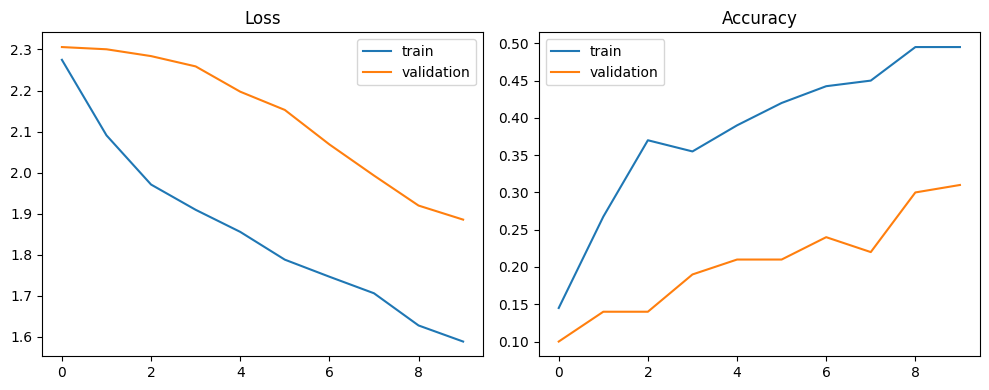

In [5]:
tr_loader, va_loader = loaders("none", SEED)
baseline_model, baseline_history = train_model(SmallCNN().to(DEVICE), tr_loader, va_loader)
print("Baseline validation:", evaluate(baseline_model, va_loader))

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(baseline_history["train_loss"], label="train")
ax[0].plot(baseline_history["val_loss"], label="validation")
ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(baseline_history["train_acc"], label="train")
ax[1].plot(baseline_history["val_acc"], label="validation")
ax[1].set_title("Accuracy"); ax[1].legend()
plt.tight_layout(); plt.show()

## 6. Ablation across configurations and seeds

In [6]:
rows = []
runs = [(c,s) for c in CONFIGS for s in SEEDS] if RUN_FULL_ABLATION else [(c,SEED) for c in CONFIGS]
for config, seed in runs:
    print("\n" + "="*50 + f"\nConfig={config}, seed={seed}")
    set_seed(seed)
    tr_loader, va_loader = loaders(config, seed)
    model = SmallCNN().to(DEVICE)
    model, hist = train_model(model, tr_loader, va_loader, use_mixup=(config=="mixup"))
    metrics = evaluate(model, va_loader)
    path = CKPT / f"{config}_seed_{seed}.pt"
    torch.save({"model_state_dict": model.state_dict(), "config": config, "seed": seed,
                "val_accuracy": metrics["accuracy"], "val_loss": metrics["loss"]}, path)
    rows.append({"config":config, "seed":seed, "val_accuracy":metrics["accuracy"],
                 "val_loss":metrics["loss"], "parameters":PARAMS, "checkpoint":str(path)})

ablation_df = pd.DataFrame(rows)
ablation_df.to_csv(OUT / "ablation_results.csv", index=False)
display(ablation_df)
summary_df = ablation_df.groupby("config")["val_accuracy"].agg(["mean","std","count"]).sort_values("mean", ascending=False)
summary_df.to_csv(OUT / "ablation_summary.csv")
display(summary_df)
best_config = summary_df.index[0]
print("Best configuration (validation only):", best_config)


Config=none, seed=17
Epoch 1/10 | train acc=0.165 | val acc=0.100
Epoch 2/10 | train acc=0.285 | val acc=0.140
Epoch 3/10 | train acc=0.338 | val acc=0.170
Epoch 4/10 | train acc=0.345 | val acc=0.200
Epoch 5/10 | train acc=0.400 | val acc=0.210
Epoch 6/10 | train acc=0.422 | val acc=0.240
Epoch 7/10 | train acc=0.425 | val acc=0.260
Epoch 8/10 | train acc=0.460 | val acc=0.250
Epoch 9/10 | train acc=0.475 | val acc=0.300
Epoch 10/10 | train acc=0.448 | val acc=0.350

Config=none, seed=42
Epoch 1/10 | train acc=0.145 | val acc=0.100
Epoch 2/10 | train acc=0.268 | val acc=0.140
Epoch 3/10 | train acc=0.370 | val acc=0.140
Epoch 4/10 | train acc=0.355 | val acc=0.190
Epoch 5/10 | train acc=0.390 | val acc=0.210
Epoch 6/10 | train acc=0.420 | val acc=0.210
Epoch 7/10 | train acc=0.443 | val acc=0.240
Epoch 8/10 | train acc=0.450 | val acc=0.220
Epoch 9/10 | train acc=0.495 | val acc=0.300
Epoch 10/10 | train acc=0.495 | val acc=0.310

Config=none, seed=123
Epoch 1/10 | train acc=0.130 | 

,config,seed,val_accuracy,val_loss,parameters,checkpoint
0,none,17,0.35,1.890872,45298,outputs\checkpoints\none_seed_17.pt
1,none,42,0.31,1.885755,45298,outputs\checkpoints\none_seed_42.pt
2,none,123,0.38,1.830036,45298,outputs\checkpoints\none_seed_123.pt
3,geometric,17,0.29,1.930426,45298,outputs\checkpoints\geometric_seed_17.pt
4,geometric,42,0.20,2.279683,45298,outputs\checkpoints\geometric_seed_42.pt
5,geometric,123,0.29,1.888387,45298,outputs\checkpoints\geometric_seed_123.pt
6,photometric,17,0.30,1.880747,45298,outputs\checkpoints\photometric_seed_17.pt
7,photometric,42,0.32,1.892566,45298,outputs\checkpoints\photometric_seed_42.pt
8,photometric,123,0.38,1.819153,45298,outputs\checkpoints\photometric_seed_123.pt
9,geometric_photometric,17,0.31,1.901096,45298,outputs\checkpoints\geometric_photometric_seed...


,mean,std,count
config,,,
none,0.346667,0.035119,3
photometric,0.333333,0.041633,3
random_erasing,0.283333,0.030551,3
mixup,0.273333,0.047258,3
geometric,0.260000,0.051962,3
geometric_photometric,0.256667,0.068069,3


Best configuration (validation only): none


## 7. Clean and shifted test evaluation

In [7]:
clean_test_ds = datasets.CIFAR10(DATA_DIR, train=False, download=False, transform=transforms.ToTensor())
clean_loader = DataLoader(clean_test_ds, batch_size=128, shuffle=False, num_workers=NUM_WORKERS)

class DeterministicShiftedCIFAR10(Dataset):
    # Fixed per-index RNG makes each image's corruption repeatable.
    def __init__(self, raw, seed=2026):
        self.raw, self.seed = raw, seed
        self.to_tensor = transforms.ToTensor()
    def __len__(self): return len(self.raw)
    def __getitem__(self, index):
        image, label = self.raw[index]
        # Local RNG states are saved/restored so data loading order doesn't alter corruption.
        py_state, np_state, torch_state = random.getstate(), np.random.get_state(), torch.random.get_rng_state()
        s = self.seed + int(index)
        random.seed(s); np.random.seed(s); torch.manual_seed(s)
        try:
            image = transforms.RandomRotation(25, interpolation=InterpolationMode.BILINEAR)(image)
            image = transforms.ColorJitter(brightness=0.3, contrast=0.3)(image)
            image = self.to_tensor(image)
            image = transforms.RandomErasing(p=1.0, scale=(0.20,0.25), ratio=(0.8,1.25), value=0)(image)
        finally:
            random.setstate(py_state); np.random.set_state(np_state); torch.random.set_rng_state(torch_state)
        return image, label

shifted_ds = DeterministicShiftedCIFAR10(test_raw, seed=2026)
shifted_loader = DataLoader(shifted_ds, batch_size=128, shuffle=False, num_workers=NUM_WORKERS)
print("Clean and shifted test sets:", len(clean_test_ds), len(shifted_ds))
print("The shifted transform is an example. Substitute your instructor's exact pipeline if provided.")

test_rows = []
for _, row in ablation_df[ablation_df["config"] == best_config].iterrows():
    seed = int(row["seed"]); path = CKPT / f"{best_config}_seed_{seed}.pt"
    ckpt = torch.load(path, map_location=DEVICE, weights_only=False)
    model = SmallCNN().to(DEVICE); model.load_state_dict(ckpt["model_state_dict"])
    clean = evaluate(model, clean_loader); shifted = evaluate(model, shifted_loader)
    test_rows.append({"config":best_config, "seed":seed,
                      "clean_accuracy":clean["accuracy"], "clean_loss":clean["loss"],
                      "shifted_accuracy":shifted["accuracy"], "shifted_loss":shifted["loss"]})

test_df = pd.DataFrame(test_rows)
test_df.to_csv(OUT / "final_test_results.csv", index=False)
display(test_df)
for col in ["clean_accuracy","shifted_accuracy"]:
    std = test_df[col].std(ddof=1) if len(test_df)>1 else 0.0
    print(f"{col}: {test_df[col].mean():.4f} ± {std:.4f}")

Clean and shifted test sets: 10000 10000
The shifted transform is an example. Substitute your instructor's exact pipeline if provided.


,config,seed,clean_accuracy,clean_loss,shifted_accuracy,shifted_loss
0,none,17,0.3119,1.862450,0.2157,2.089252
1,none,42,0.3249,1.846888,0.1811,2.160016
2,none,123,0.3283,1.846461,0.1744,2.357324


clean_accuracy: 0.3217 ± 0.0087
shifted_accuracy: 0.1904 ± 0.0222


## 8. Error analysis and test-time augmentation

Clean accuracy: 0.3119 | incorrect: 6881


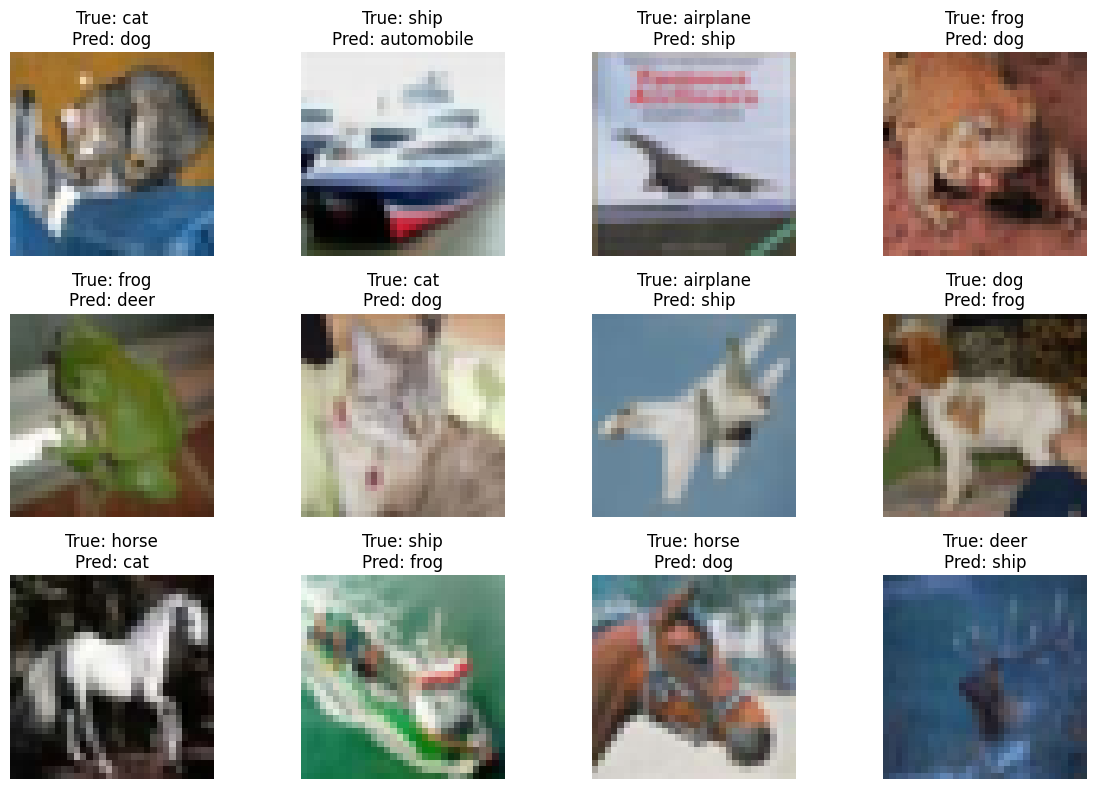

              precision    recall  f1-score   support

    airplane       0.42      0.37      0.39      1000
  automobile       0.47      0.27      0.35      1000
        bird       0.33      0.10      0.16      1000
         cat       0.12      0.10      0.11      1000
        deer       0.36      0.15      0.21      1000
         dog       0.22      0.58      0.32      1000
        frog       0.29      0.66      0.40      1000
       horse       0.37      0.09      0.15      1000
        ship       0.41      0.48      0.44      1000
       truck       0.53      0.31      0.39      1000

    accuracy                           0.31     10000
   macro avg       0.35      0.31      0.29     10000
weighted avg       0.35      0.31      0.29     10000



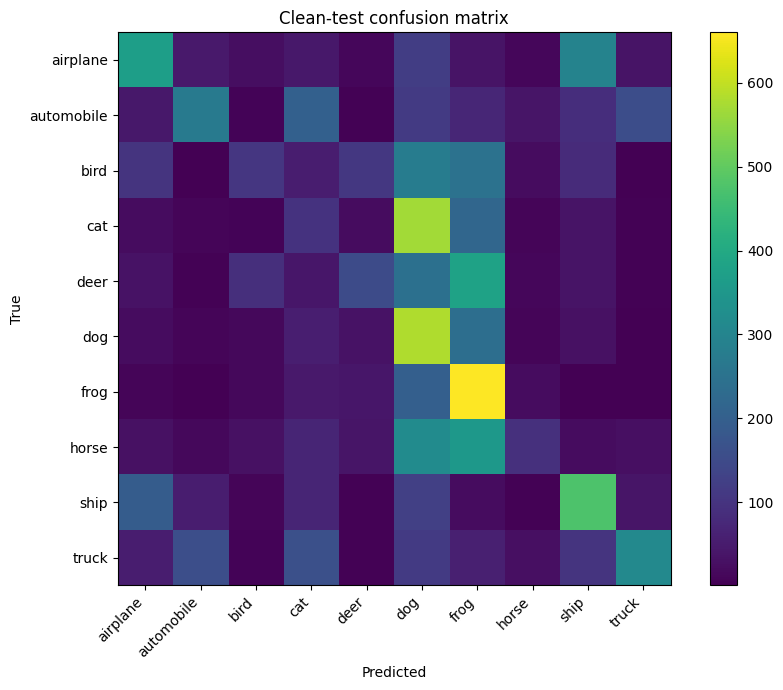

,true_class,predicted_class,count
31,cat,dog,568
41,deer,frog,381
69,horse,frog,352
68,horse,dog,319
7,airplane,ship,297
22,bird,dog,278
23,bird,frog,250
40,deer,dog,245
50,dog,frog,238
32,cat,frog,219


,method,clean_test_accuracy
0,Standard inference,0.3119
1,Horizontal-flip TTA,0.3134


In [8]:
first_row = ablation_df[ablation_df["config"] == best_config].iloc[0]
analysis_seed = int(first_row["seed"])
ckpt = torch.load(CKPT / f"{best_config}_seed_{analysis_seed}.pt", map_location=DEVICE, weights_only=False)
analysis_model = SmallCNN().to(DEVICE); analysis_model.load_state_dict(ckpt["model_state_dict"])
result = evaluate(analysis_model, clean_loader, predictions=True)
labels, preds = result["labels"], result["predictions"]
wrong = np.where(labels != preds)[0]
print("Clean accuracy:", round(result["accuracy"],4), "| incorrect:", len(wrong))

fig, axes = plt.subplots(3,4,figsize=(12,8)); axes = axes.flatten()
for j, ax in enumerate(axes):
    if j < min(12, len(wrong)):
        idx = int(wrong[j]); img, true_label = clean_test_ds[idx]
        ax.imshow(img.permute(1,2,0).numpy())
        ax.set_title(f"True: {CLASS_NAMES[true_label]}\nPred: {CLASS_NAMES[int(preds[idx])]}")
    ax.axis("off")
plt.tight_layout(); plt.show()

print(classification_report(labels, preds, target_names=CLASS_NAMES, zero_division=0))
cm = confusion_matrix(labels, preds)
plt.figure(figsize=(9,7)); plt.imshow(cm); plt.colorbar()
plt.xticks(range(10), CLASS_NAMES, rotation=45, ha="right")
plt.yticks(range(10), CLASS_NAMES)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Clean-test confusion matrix")
plt.tight_layout(); plt.show()

pairs = [{"true_class":CLASS_NAMES[i], "predicted_class":CLASS_NAMES[j], "count":int(cm[i,j])}
         for i in range(10) for j in range(10) if i != j and cm[i,j] > 0]
if pairs: display(pd.DataFrame(pairs).sort_values("count", ascending=False).head(10))

def evaluate_flip_tta(model, loader):
    model.eval(); correct=0; total=0
    with torch.no_grad():
        for x,y in loader:
            x,y=x.to(DEVICE),y.to(DEVICE)
            p1=torch.softmax(model(x),dim=1)
            p2=torch.softmax(model(torch.flip(x,dims=[3])),dim=1)
            pred=((p1+p2)/2).argmax(1)
            correct += (pred==y).sum().item(); total += y.size(0)
    return correct/max(total,1)

tta_acc = evaluate_flip_tta(analysis_model, clean_loader)
tta_df = pd.DataFrame([
    {"method":"Standard inference","clean_test_accuracy":result["accuracy"]},
    {"method":"Horizontal-flip TTA","clean_test_accuracy":tta_acc}
])
display(tta_df)
tta_df.to_csv(OUT / "tta_comparison.csv", index=False)